#### 2. Pemeriksaan dan Pembersihan Data

##### 2.A. Pembacaan dan Pemeriksaan Awal

Tanpa mengubah data mentah. Pemeriksaan awal
Cek jumlah baris dan kolom, nama kolom, serta contoh isi data.

In [6]:
from pathlib import Path
import pandas as pd

In [7]:

DATA_DIR = Path("../KopiNusa_TakeHome")

anggota_raw = pd.read_csv(
    DATA_DIR / "anggota.csv",
    dtype="string",
    keep_default_na=False
)

transaksi_raw = pd.read_csv(
    DATA_DIR / "transaksi.csv",
    dtype="string",
    keep_default_na=False
)

In [8]:
ringkasan_awal = pd.DataFrame({
    "tabel": ["anggota", "transaksi"],
    "jumlah_baris": [
        len(anggota_raw),
        len(transaksi_raw)
    ],
    "jumlah_kolom": [
        anggota_raw.shape[1],
        transaksi_raw.shape[1]
    ]
})

display(ringkasan_awal)

,tabel,jumlah_baris,jumlah_kolom
0,anggota,1500,9
1,transaksi,36175,9


In [9]:
struktur_awal = pd.concat(
    [
        pd.DataFrame({
            "tabel": "anggota",
            "kolom": anggota_raw.columns,
            "tipe_saat_audit": anggota_raw.dtypes.astype(str).to_numpy()
        }),
        pd.DataFrame({
            "tabel": "transaksi",
            "kolom": transaksi_raw.columns,
            "tipe_saat_audit": transaksi_raw.dtypes.astype(str).to_numpy()
        })
    ],
    ignore_index=True
)

display(struktur_awal)
display(anggota_raw.head())
display(transaksi_raw.head())

,tabel,kolom,tipe_saat_audit
0,anggota,id_anggota,string
1,anggota,usia,string
2,anggota,kota,string
3,anggota,tanggal_daftar,string
4,anggota,tingkat,string
5,anggota,pakai_aplikasi,string
6,anggota,penghasilan_juta,string
7,anggota,voucher_winback,string
8,anggota,berhenti,string
9,transaksi,id_transaksi,string


,id_anggota,usia,kota,tanggal_daftar,tingkat,pakai_aplikasi,penghasilan_juta,voucher_winback,berhenti
0,00354,41,Yogyakarta,12/12/2023,Silver,ya,11.8,0,tidak
1,01496,20,Sleman,12/11/2025,Silver,ya,8.8,0,tidak
2,02805,35,Bantul,05/08/2024,Silver,ya,3.9,0,tidak
3,00537,29,Sleman,24/03/2023,Silver,ya,6.1,0,tidak
4,03036,35,Yogyakarta,07/07/2025,Silver,tidak,8.8,0,tidak


,id_transaksi,id_anggota,waktu,cabang,kategori,jumlah_item,total,pakai_promo,metode_bayar
0,T009292,03569,2026-02-14 21:03,C08,kopi,1,29700,tidak,QRIS
1,T019288,00318,2026-04-11 07:08,C07,non-kopi,3,75900,tidak,aplikasi
2,T032136,00998,2026-06-15 13:33,C10,kopi,2,43300,tidak,aplikasi
3,T026989,00712,2026-05-22 12:53,C15,kopi,4,159800,tidak,QRIS
4,T025743,00208,2026-05-15 14:59,C12,kopi,1,28400,tidak,QRIS


##### Identifikasi Masalah Kualitas Data

Pemeriksaan sel kosong, baris identik dan pengulangan ID pada masing-masing tabel. 
Hasil pemeriksaan digunakan untuk menentukan penanganan.

In [11]:
anggota_audit = anggota_raw.copy()
transaksi_audit = transaksi_raw.copy()

anggota_audit = anggota_audit.replace(
    r"^\s*$", pd.NA, regex=True
)

transaksi_audit = transaksi_audit.replace(
    r"^\s*$", pd.NA, regex=True
)

In [ ]:
def profile(df):
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "n_missing": df.isna().sum(), # JUmlah nilai missing setiap kolom
        "pct_missing": (df.isna().mean() * 100).round(1), # Persentase
        "n_unique": df.nunique(dropna=True) # Jumlah nilai berbeda tidak termasuk missing
    }).sort_values("pct_missing", ascending=False)

display(profile(anggota_audit))
display(profile(transaksi_audit))

,dtype,n_missing,pct_missing,n_unique
penghasilan_juta,string,138,9.2,160
id_anggota,string,0,0.0,1500
usia,string,0,0.0,53
kota,string,0,0.0,19
tanggal_daftar,string,0,0.0,826
tingkat,string,0,0.0,3
pakai_aplikasi,string,0,0.0,2
voucher_winback,string,0,0.0,2
berhenti,string,0,0.0,2


,dtype,n_missing,pct_missing,n_unique
id_transaksi,string,0,0.0,35640
id_anggota,string,0,0.0,1559
waktu,string,0,0.0,31393
cabang,string,0,0.0,20
kategori,string,0,0.0,3
jumlah_item,string,0,0.0,21
total,string,0,0.0,1734
pakai_promo,string,0,0.0,2
metode_bayar,string,0,0.0,3


##### Periksa Duplikasi dan Pengulangan ID

In [ ]:
print(
    "Duplikat identik tambahan pada anggota:",
    anggota_raw.duplicated().sum()
)

print(
    "Duplikat identik tambahan pada transaksi:",
    transaksi_raw.duplicated().sum()
)

print(
    "Baris dengan ID anggota berulang:",
    anggota_audit.duplicated(
        subset="id_anggota", keep=False
    ).sum()
)

print(
    "Baris dengan ID transaksi berulang:",
    transaksi_audit.duplicated(
        subset="id_transaksi", keep=False
    ).sum()
)

jumlah_per_id = transaksi_audit["id_transaksi"].value_counts()

distribusi_pengulangan = (
    jumlah_per_id.value_counts()
    .sort_index()
    .rename_axis("jumlah_kemunculan_per_id")
    .reset_index(name="jumlah_id_transaksi")
)

display(distribusi_pengulangan)

transaksi_tanpa_duplikat_identik = (
    transaksi_audit.drop_duplicates().copy()
)

konflik_id = transaksi_tanpa_duplikat_identik.loc[
    transaksi_tanpa_duplikat_identik.duplicated(
        subset="id_transaksi",
        keep=False
    )
].sort_values("id_transaksi")

print("Baris sebelum:", len(transaksi_audit))
print("Baris setelah:", len(transaksi_tanpa_duplikat_identik))
print("Salinan identik disisihkan:",
      len(transaksi_audit) - len(transaksi_tanpa_duplikat_identik))
print("Baris dengan ID berulang yang masih tersisa:", len(konflik_id))

display(konflik_id.head(20))

Duplikat identik tambahan pada anggota: 0
Duplikat identik tambahan pada transaksi: 535
Baris dengan ID anggota berulang: 0
Baris dengan ID transaksi berulang: 1070


,jumlah_kemunculan_per_id,jumlah_id_transaksi
0,1,35105
1,2,535


Baris sebelum: 36175
Baris setelah: 35640
Salinan identik disisihkan: 535
Baris dengan ID berulang yang masih tersisa: 0


,id_transaksi,id_anggota,waktu,cabang,kategori,jumlah_item,total,pakai_promo,metode_bayar


##### Pemeriksaan Kecocokan ID Anggota Antartabel

In [23]:
anggota_clean = anggota_audit.copy()
transaksi_clean = transaksi_tanpa_duplikat_identik.copy()

In [35]:
mask_tidak_cocok = ~transaksi_clean["id_anggota"].isin(
    anggota_clean["id_anggota"]
)

transaksi_tanpa_pasangan = transaksi_clean.loc[
    mask_tidak_cocok
].copy()

print(
    "Jumlah transaksi tanpa pasangan anggota:",
    len(transaksi_tanpa_pasangan)
)

print(
    "Jumlah ID anggota berbeda tanpa pasangan:",
    transaksi_tanpa_pasangan["id_anggota"].nunique()
)

display(transaksi_tanpa_pasangan.head(20))

Jumlah transaksi tanpa pasangan anggota: 240
Jumlah ID anggota berbeda tanpa pasangan: 60


,id_transaksi,id_anggota,waktu,cabang,kategori,jumlah_item,total,pakai_promo,metode_bayar
121,T009041,04202,2026-02-13 16:42,C05,kopi,4,74200,tidak,aplikasi
203,T014397,04024,2026-03-13 17:29,C18,makanan,4,161800,tidak,tunai
487,T034285,04248,2026-06-25 07:40,C04,non-kopi,2,65300,tidak,aplikasi
535,T010568,04251,2026-02-20 19:49,C09,kopi,2,109800,tidak,QRIS
1078,T024599,04054,2026-05-09 19:54,C19,non-kopi,1,17400,ya,aplikasi
1159,T015205,04251,2026-03-18 14:57,C20,kopi,1,37600,tidak,aplikasi
1183,T023819,04181,2026-05-05 19:00,C07,kopi,1,30300,ya,QRIS
1284,T006470,04036,2026-02-01 07:10,C11,kopi,1,25900,tidak,QRIS
1422,T017154,04174,2026-03-29 21:54,C14,non-kopi,1,39600,ya,aplikasi
1461,T000188,04377,2026-01-01 18:27,C08,kopi,1,29000,tidak,aplikasi


In [36]:
display(
    transaksi_tanpa_pasangan["id_anggota"]
    .value_counts(dropna=False)
    .rename_axis("id_anggota")
    .reset_index(name="jumlah_transaksi")
)

,id_anggota,jumlah_transaksi
0,04251,9
1,04179,8
2,04314,8
3,04022,8
4,04024,7
5,04128,7
6,04230,7
7,04343,7
8,04168,7
9,04236,7


##### 2.B. Mekanisme Hilangnya Penghasilan dan Penanganannya

Ditemukan 138 nilai kosong pada kolom penghasilan_juta atau 9,2% <br>
dari seluruh anggota. Pola kehilangan diperiksa dengan membandingkan<br>
karakteristik anggota yang memiliki dan tidak memiliki data penghasilan.<br>

In [38]:
anggota_missing = anggota_clean.copy()

anggota_missing["penghasilan_kosong"] = (
    anggota_missing["penghasilan_juta"].isna()
)

display(
    anggota_missing["penghasilan_kosong"].value_counts()
)

penghasilan_kosong
False    1362
True      138
Name: count, dtype: int64

In [39]:
anggota_missing["usia_angka"] = pd.to_numeric(
    anggota_missing["usia"],
    errors="coerce"
)

print(
    "Usia yang terisi tetapi gagal dikonversi:",
    (
        anggota_missing["usia"].notna()
        & anggota_missing["usia_angka"].isna()
    ).sum()
)

perbandingan_usia = (
    anggota_missing
    .groupby("penghasilan_kosong")["usia_angka"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

display(perbandingan_usia)

Usia yang terisi tetapi gagal dikonversi: 0


,count,mean,median,min,max
penghasilan_kosong,,,,,
False,1362,41.72,30.0,-1,999
True,138,63.22,41.5,-1,999


In [40]:
missing_per_tingkat = (
    anggota_missing.groupby("tingkat")["penghasilan_kosong"]
    .agg(["size", "sum", "mean"])
    .rename(columns={
        "size": "jumlah_anggota",
        "sum": "jumlah_penghasilan_kosong",
        "mean": "persentase_kosong"
    })
)

missing_per_tingkat["persentase_kosong"] = (
    missing_per_tingkat["persentase_kosong"] * 100
).round(2)

display(missing_per_tingkat)

,jumlah_anggota,jumlah_penghasilan_kosong,persentase_kosong
tingkat,,,
Gold,300,26,8.67
Platinum,150,8,5.33
Silver,1050,104,9.90


In [41]:
missing_per_aplikasi = (
    anggota_missing.groupby("pakai_aplikasi")["penghasilan_kosong"]
    .agg(["size", "sum", "mean"])
    .rename(columns={
        "size": "jumlah_anggota",
        "sum": "jumlah_penghasilan_kosong",
        "mean": "persentase_kosong"
    })
)

missing_per_aplikasi["persentase_kosong"] = (
    missing_per_aplikasi["persentase_kosong"] * 100
).round(2)

display(missing_per_aplikasi)

,jumlah_anggota,jumlah_penghasilan_kosong,persentase_kosong
pakai_aplikasi,,,
tidak,477,67,14.05
ya,1023,71,6.94


##### Tandai usia di luar rentang sebagai missing

In [42]:
usia_tidak_valid = (
    anggota_missing["usia_angka"].notna()
    & ~anggota_missing["usia_angka"].between(17, 70)
)

print("Jumlah usia tidak valid:", usia_tidak_valid.sum())

display(
    anggota_missing.loc[
        usia_tidak_valid, "usia"
    ].value_counts()
)

anggota_missing.loc[
    usia_tidak_valid, "usia_angka"
] = pd.NA

Jumlah usia tidak valid: 44


usia
-1     26
999    18
Name: count, dtype: int64[pyarrow]

##### Hitung ulang perbandingan usia

In [53]:
perbandingan_usia_valid = (
    anggota_missing
    .groupby("penghasilan_kosong")["usia_angka"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
)

display(perbandingan_usia_valid)

,count,mean,median,min,max
penghasilan_kosong,,,,,
False,1322,31.67,30.0,18,70
True,134,42.75,41.0,19,70


##### Melihat pola menurut kelompok usia

In [54]:
anggota_missing["kelompok_usia"] = pd.cut(
    anggota_missing["usia_angka"].astype("float64"),
    bins=[16, 29, 39, 49, 59, 70],
    labels=["17–29", "30–39", "40–49", "50–59", "60–70"]
)

missing_per_usia = (
    anggota_missing
    .groupby("kelompok_usia", observed=True)["penghasilan_kosong"]
    .agg(["size", "sum", "mean"])
    .rename(columns={
        "size": "jumlah_anggota",
        "sum": "jumlah_penghasilan_kosong",
        "mean": "persentase_kosong"
    })
)

missing_per_usia["persentase_kosong"] = (
    missing_per_usia["persentase_kosong"] * 100
).round(2)

display(missing_per_usia)

,jumlah_anggota,jumlah_penghasilan_kosong,persentase_kosong
kelompok_usia,,,
17–29,656,20,3.05
30–39,487,41,8.42
40–49,207,30,14.49
50–59,73,30,41.10
60–70,33,13,39.39


In [55]:
anggota_clean["usia"] = anggota_missing["usia_angka"].copy()

anggota_clean["penghasilan_was_missing"] = (
    anggota_clean["penghasilan_juta"].isna().astype("int8")
)

penghasilan_angka = pd.to_numeric(
    anggota_clean["penghasilan_juta"],
    errors="coerce"
)

gagal_konversi = (
    anggota_clean["penghasilan_juta"].notna()
    & penghasilan_angka.isna()
)

print(
    "Penghasilan terisi tetapi gagal dikonversi:",
    gagal_konversi.sum()
)

display(
    anggota_clean.loc[
        gagal_konversi,
        ["id_anggota", "penghasilan_juta"]
    ]
)

display(penghasilan_angka.describe())


Penghasilan terisi tetapi gagal dikonversi: 0


,id_anggota,penghasilan_juta


count      1362.0
mean     6.365712
std      3.353615
min           1.2
25%           4.0
50%           5.7
75%           7.9
max          24.8
Name: penghasilan_juta, dtype: Float64

In [56]:
anggota_clean["penghasilan_juta"] = penghasilan_angka.copy()

anggota_deskriptif = anggota_clean.copy()

anggota_deskriptif["kelompok_usia"] = pd.cut(
    anggota_deskriptif["usia"].astype("float64"),
    bins=[16, 29, 39, 49, 59, 70],
    labels=["17–29", "30–39", "40–49", "50–59", "60–70"]
)

median_per_usia = (
    anggota_deskriptif
    .groupby("kelompok_usia", observed=True)["penghasilan_juta"]
    .median()
)

median_keseluruhan = anggota_deskriptif["penghasilan_juta"].median()

display(
    median_per_usia.to_frame(name="median_penghasilan_juta")
)

print("Median keseluruhan:", median_keseluruhan)

,median_penghasilan_juta
kelompok_usia,
17–29,5.2
30–39,5.9
40–49,6.1
50–59,8.3
60–70,9.15


Median keseluruhan: 5.7


In [57]:
median_untuk_anggota = (
    anggota_deskriptif
    .groupby("kelompok_usia", observed=True)["penghasilan_juta"]
    .transform("median")
)

penghasilan_kosong = anggota_deskriptif["penghasilan_juta"].isna()

pakai_median_kelompok = (
    penghasilan_kosong & median_untuk_anggota.notna()
)

pakai_fallback = (
    penghasilan_kosong & median_untuk_anggota.isna()
)

anggota_deskriptif["penghasilan_juta_imputasi"] = (
    anggota_deskriptif["penghasilan_juta"]
    .fillna(median_untuk_anggota)
    .fillna(median_keseluruhan)
)

print("Diisi dengan median kelompok usia:",
      pakai_median_kelompok.sum())

print("Diisi dengan median keseluruhan:",
      pakai_fallback.sum())

print("Missing sebelum:",
      anggota_deskriptif["penghasilan_juta"].isna().sum())

print("Missing setelah:",
      anggota_deskriptif["penghasilan_juta_imputasi"].isna().sum())

print("Jumlah anggota:", len(anggota_deskriptif))

Diisi dengan median kelompok usia: 134
Diisi dengan median keseluruhan: 4
Missing sebelum: 138
Missing setelah: 0
Jumlah anggota: 1500


#### C. Nilai Total Tidak Wajar dan Penanganannya

Pemeriksaan dilakukan pada total dan jumlah_item.

In [61]:
transaksi_nilai = transaksi_tanpa_duplikat_identik.copy()

print("Jumlah transaksi dalam audit nilai:", len(transaksi_nilai))

for kolom in ["total", "jumlah_item"]:
    transaksi_nilai[f"{kolom}_angka"] = pd.to_numeric(
        transaksi_nilai[kolom],
        errors="coerce"
    )

    gagal = (
        transaksi_nilai[kolom].notna()
        & transaksi_nilai[f"{kolom}_angka"].isna()
    )

    print(f"{kolom} terisi tetapi gagal dikonversi:", gagal.sum())

    display(
        transaksi_nilai.loc[
            gagal,
            ["id_transaksi", kolom]
        ].head(20)
    )

item_valid = (
    transaksi_nilai["jumlah_item_angka"].gt(0).fillna(False)
    & transaksi_nilai["jumlah_item_angka"]
      .mod(1).eq(0).fillna(False)
)

transaksi_nilai["rata_rata_nilai_per_item"] = (
    transaksi_nilai["total_angka"]
    / transaksi_nilai["jumlah_item_angka"].where(item_valid)
)

Jumlah transaksi dalam audit nilai: 35640
total terisi tetapi gagal dikonversi: 0


,id_transaksi,total


jumlah_item terisi tetapi gagal dikonversi: 0


,id_transaksi,jumlah_item


In [62]:
display(
    transaksi_nilai[
        ["total_angka", "jumlah_item_angka"]
    ].describe(
        percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]
    )
)

item_nonpositif = (
    transaksi_nilai["jumlah_item_angka"].le(0).fillna(False)
)

item_pecahan = (
    transaksi_nilai["jumlah_item_angka"]
    .mod(1).ne(0).fillna(False)
)

total_negatif = (
    transaksi_nilai["total_angka"].lt(0).fillna(False)
)

total_nol = (
    transaksi_nilai["total_angka"].eq(0).fillna(False)
)

print("Jumlah item nol atau negatif:", item_nonpositif.sum())
print("Jumlah item berupa pecahan:", item_pecahan.sum())
print("Total negatif:", total_negatif.sum())
print("Total nol:", total_nol.sum())

perlu_diperiksa = (
    item_nonpositif | item_pecahan | total_negatif | total_nol
)

display(
    transaksi_nilai.loc[
        perlu_diperiksa,
        [
            "id_transaksi",
            "id_anggota",
            "kategori",
            "jumlah_item_angka",
            "total_angka",
            "pakai_promo"
        ]
    ]
)

,total_angka,jumlah_item_angka
count,35640.0,35640.0
mean,56951.982323,1.814001
std,482136.483957,2.143849
min,-102200.0,1.0
25%,25500.0,1.0
50%,38300.0,1.0
75%,62800.0,2.0
95%,112200.0,4.0
99%,158700.0,4.0
max,35000000.0,120.0


Jumlah item nol atau negatif: 0
Jumlah item berupa pecahan: 0
Total negatif: 5
Total nol: 7


,id_transaksi,id_anggota,kategori,jumlah_item_angka,total_angka,pakai_promo
3370,T018423,02688,kopi,3,-88900,tidak
3745,T000687,03605,kopi,1,0,tidak
4912,T014975,02184,kopi,2,0,tidak
5540,T000833,03793,kopi,1,-20800,tidak
6625,T026140,00067,makanan,3,0,tidak
7923,T022262,02045,kopi,1,-22200,tidak
10089,T019617,01096,kopi,3,-102200,tidak
10476,T005959,00673,kopi,2,0,ya
20917,T013089,00096,kopi,3,0,tidak
24293,T022973,02456,non-kopi,2,-32100,tidak


In [63]:
kolom_tampil = [
    "id_transaksi",
    "id_anggota",
    "kategori",
    "jumlah_item_angka",
    "total_angka",
    "rata_rata_nilai_per_item",
    "pakai_promo"
]

transaksi_besar = transaksi_nilai.loc[
    transaksi_nilai["total_angka"] >= 1_000_000
].copy()

print(
    "Jumlah transaksi dengan total minimal Rp1 juta:",
    len(transaksi_besar)
)

display(
    transaksi_besar[kolom_tampil]
    .sort_values("total_angka", ascending=False)
)

pembanding = transaksi_nilai.loc[
    (transaksi_nilai["total_angka"] > 0)
    & (transaksi_nilai["total_angka"] < 1_000_000)
    & item_valid
].copy()

print("Ringkasan nilai per item pada transaksi pembanding:")

display(
    pembanding.groupby("kategori")["rata_rata_nilai_per_item"]
    .agg(["count", "median", "min", "max"])
    .round(2)
)

Jumlah transaksi dengan total minimal Rp1 juta: 26


,id_transaksi,id_anggota,kategori,jumlah_item_angka,total_angka,rata_rata_nilai_per_item,pakai_promo
14855,T018161,02081,non-kopi,1,35000000,35000000.0,ya
885,T008108,01012,non-kopi,1,35000000,35000000.0,ya
1876,T010999,03531,kopi,1,33000000,33000000.0,tidak
15728,T001695,02091,kopi,1,33000000,33000000.0,ya
8029,T018710,03950,makanan,1,29000000,29000000.0,tidak
34855,T010279,03182,kopi,1,29000000,29000000.0,tidak
710,T033833,01323,non-kopi,1,28000000,28000000.0,tidak
13946,T016270,01812,kopi,1,25000000,25000000.0,ya
10639,T016533,00501,kopi,1,22000000,22000000.0,tidak
4217,T024479,01164,kopi,120,2907840,24232.0,tidak


Ringkasan nilai per item pada transaksi pembanding:


,count,median,min,max
kategori,,,,
kopi,21547,25750.0,7100.0,111925.0
makanan,6988,25900.0,8700.0,86500.0
non-kopi,7067,25900.0,8400.0,82200.0


In [64]:
# Sembilan transaksi satu item bernilai Rp22–35 juta
# yang ditemukan pada pemeriksaan C3
id_dugaan_salah_skala = [
    "T018161",
    "T008108",
    "T010999",
    "T001695",
    "T018710",
    "T010279",
    "T033833",
    "T016270",
    "T016533"
]

transaksi_nilai["status_audit_total"] = "tidak_ditandai"

transaksi_nilai.loc[
    transaksi_nilai["total_angka"] < 0,
    "status_audit_total"
] = "total_negatif_perlu_klarifikasi"

transaksi_nilai.loc[
    transaksi_nilai["total_angka"] == 0,
    "status_audit_total"
] = "total_nol_perlu_klarifikasi"

transaksi_nilai.loc[
    transaksi_nilai["id_transaksi"].isin(id_dugaan_salah_skala),
    "status_audit_total"
] = "dugaan_salah_skala"

transaksi_nilai["perlu_klarifikasi_total"] = (
    transaksi_nilai["status_audit_total"] != "tidak_ditandai"
)

transaksi_perlu_klarifikasi = transaksi_nilai.loc[
    transaksi_nilai["perlu_klarifikasi_total"]
].copy()

print("Ringkasan status audit total:")
display(
    transaksi_nilai["status_audit_total"]
    .value_counts()
    .rename_axis("status_audit_total")
    .reset_index(name="jumlah_transaksi")
)

print(
    "Jumlah transaksi yang perlu diklarifikasi:",
    len(transaksi_perlu_klarifikasi)
)

print(
    "Jumlah seluruh transaksi setelah penandaan:",
    len(transaksi_nilai)
)

display(
    transaksi_perlu_klarifikasi[
        [
            "id_transaksi",
            "id_anggota",
            "kategori",
            "jumlah_item_angka",
            "total_angka",
            "rata_rata_nilai_per_item",
            "pakai_promo",
            "status_audit_total"
        ]
    ].sort_values(
        ["status_audit_total", "total_angka"]
    )
)

Ringkasan status audit total:


,status_audit_total,jumlah_transaksi
0,tidak_ditandai,35619
1,dugaan_salah_skala,9
2,total_nol_perlu_klarifikasi,7
3,total_negatif_perlu_klarifikasi,5


Jumlah transaksi yang perlu diklarifikasi: 21
Jumlah seluruh transaksi setelah penandaan: 35640


,id_transaksi,id_anggota,kategori,jumlah_item_angka,total_angka,rata_rata_nilai_per_item,pakai_promo,status_audit_total
10639,T016533,00501,kopi,1,22000000,22000000.0,tidak,dugaan_salah_skala
13946,T016270,01812,kopi,1,25000000,25000000.0,ya,dugaan_salah_skala
710,T033833,01323,non-kopi,1,28000000,28000000.0,tidak,dugaan_salah_skala
8029,T018710,03950,makanan,1,29000000,29000000.0,tidak,dugaan_salah_skala
34855,T010279,03182,kopi,1,29000000,29000000.0,tidak,dugaan_salah_skala
1876,T010999,03531,kopi,1,33000000,33000000.0,tidak,dugaan_salah_skala
15728,T001695,02091,kopi,1,33000000,33000000.0,ya,dugaan_salah_skala
885,T008108,01012,non-kopi,1,35000000,35000000.0,ya,dugaan_salah_skala
14855,T018161,02081,non-kopi,1,35000000,35000000.0,ya,dugaan_salah_skala
10089,T019617,01096,kopi,3,-102200,-34066.666667,tidak,total_negatif_perlu_klarifikasi


##### Keputusan Penggunaan Nominal dalam Analisis Belanja

Nominal asli dan seluruh baris transaksi tetap dipertahankan. <br>
Untuk analisis belanja, dibuat kolom nominal terpisah.

#### 3. Eksplorasi Data

Eksplorasi dilakukan untuk memahami sebaran total belanja per anggota </br>
serta membandingkan persentase berhenti antara pengguna dan bukan</br>
pengguna aplikasi.</br>

Hasil eksplorasi digunakan untuk menemukan pola</br>
dan penjelasan alternatif, bukan untuk membuktikan hubungan sebab-akibat.</br>

In [65]:
kolom_anggota_diperlukan = [
    "id_anggota",
    "pakai_aplikasi",
    "berhenti",
    "tingkat"
]

kolom_belum_ada = [
    kolom
    for kolom in kolom_anggota_diperlukan
    if kolom not in anggota_clean.columns
]

if kolom_belum_ada:
    raise ValueError(
        f"Kolom yang belum tersedia: {kolom_belum_ada}"
    )

print("Jumlah baris anggota:", len(anggota_clean))
print(
    "Jumlah ID anggota unik:",
    anggota_clean["id_anggota"].nunique()
)
print(
    "Jumlah ID anggota missing:",
    anggota_clean["id_anggota"].isna().sum()
)
print(
    "Jumlah baris dengan ID anggota duplikat "
    "(termasuk seluruh kemunculannya):",
    anggota_clean["id_anggota"].duplicated(keep=False).sum()
)

print("\nTipe data kolom yang diperlukan:")
display(
    anggota_clean[kolom_anggota_diperlukan]
    .dtypes.astype(str)
    .rename("tipe_data")
    .to_frame()
)

for kolom in ["pakai_aplikasi", "berhenti", "tingkat"]:
    print(f"\nIsi kolom {kolom}:")
    display(
        anggota_clean[kolom]
        .value_counts(dropna=False)
        .rename_axis(kolom)
        .reset_index(name="jumlah_anggota")
    )

print("\nContoh data anggota:")
display(
    anggota_clean[kolom_anggota_diperlukan].head(10)
)

print("\nJumlah transaksi dalam tabel audit:", len(transaksi_nilai))
print("Tipe ID anggota pada transaksi:",
      transaksi_nilai["id_anggota"].dtype)

print("\nRingkasan status audit total:")
display(
    transaksi_nilai["status_audit_total"]
    .value_counts(dropna=False)
    .rename_axis("status_audit_total")
    .reset_index(name="jumlah_transaksi")
)

Jumlah baris anggota: 1500
Jumlah ID anggota unik: 1500
Jumlah ID anggota missing: 0
Jumlah baris dengan ID anggota duplikat (termasuk seluruh kemunculannya): 0

Tipe data kolom yang diperlukan:


,tipe_data
id_anggota,string
pakai_aplikasi,string
berhenti,string
tingkat,string



Isi kolom pakai_aplikasi:


,pakai_aplikasi,jumlah_anggota
0,ya,1023
1,tidak,477



Isi kolom berhenti:


...

,tingkat,jumlah_anggota
0,Silver,1050
1,Gold,300
2,Platinum,150



Contoh data anggota:


,id_anggota,pakai_aplikasi,berhenti,tingkat
0,00354,ya,tidak,Silver
1,01496,ya,tidak,Silver
2,02805,ya,tidak,Silver
3,00537,ya,tidak,Silver
4,03036,tidak,tidak,Silver
5,01033,ya,tidak,Silver
6,00085,ya,ya,Silver
7,03399,ya,tidak,Silver
8,03071,ya,tidak,Gold
9,01368,ya,tidak,Gold



Jumlah transaksi dalam tabel audit: 35640
Tipe ID anggota pada transaksi: string

Ringkasan status audit total:


,status_audit_total,jumlah_transaksi
0,tidak_ditandai,35619
1,dugaan_salah_skala,9
2,total_nol_perlu_klarifikasi,7
3,total_negatif_perlu_klarifikasi,5


In [66]:
anggota_eda = anggota_clean[
    ["id_anggota", "pakai_aplikasi", "berhenti", "tingkat"]
].copy()

assert anggota_eda["id_anggota"].notna().all()
assert anggota_eda["id_anggota"].is_unique

for kolom in ["pakai_aplikasi", "berhenti"]:
    assert anggota_eda[kolom].isin(["ya", "tidak"]).all(), (
        f"Ada nilai tidak sesuai pada {kolom}"
    )

assert anggota_eda["tingkat"].isin(
    ["Silver", "Gold", "Platinum"]
).all()

anggota_eda["berhenti_flag"] = (
    anggota_eda["berhenti"].map({"ya": 1, "tidak": 0})
)

ringkasan_aplikasi = (
    anggota_eda.groupby("pakai_aplikasi", observed=True)
    .agg(
        jumlah_anggota=("id_anggota", "size"),
        jumlah_berhenti=("berhenti_flag", "sum")
    )
    .reindex(["tidak", "ya"])
)

ringkasan_aplikasi["persen_berhenti"] = (
    ringkasan_aplikasi["jumlah_berhenti"]
    / ringkasan_aplikasi["jumlah_anggota"] * 100
)

ringkasan_tingkat = (
    anggota_eda.groupby(
        ["tingkat", "pakai_aplikasi"],
        observed=True
    )
    .agg(
        jumlah_anggota=("id_anggota", "size"),
        jumlah_berhenti=("berhenti_flag", "sum")
    )
    .reset_index()
)

ringkasan_tingkat["persen_berhenti"] = (
    ringkasan_tingkat["jumlah_berhenti"]
    / ringkasan_tingkat["jumlah_anggota"] * 100
)

komposisi_tingkat = pd.crosstab(
    anggota_eda["tingkat"],
    anggota_eda["pakai_aplikasi"],
    normalize="columns"
).reindex(
    index=["Silver", "Gold", "Platinum"],
    columns=["tidak", "ya"]
) * 100

print("Angka berhenti berdasarkan penggunaan aplikasi:")
display(ringkasan_aplikasi.round(2))

print("Angka berhenti pada setiap tingkat keanggotaan:")
display(ringkasan_tingkat.round(2))

print("Komposisi tingkat dalam setiap kelompok aplikasi (%):")
display(komposisi_tingkat.round(2))

Angka berhenti berdasarkan penggunaan aplikasi:


,jumlah_anggota,jumlah_berhenti,persen_berhenti
pakai_aplikasi,,,
tidak,477,106,22.22
ya,1023,125,12.22


Angka berhenti pada setiap tingkat keanggotaan:


,tingkat,pakai_aplikasi,jumlah_anggota,jumlah_berhenti,persen_berhenti
0,Gold,tidak,68,14,20.59
1,Gold,ya,232,14,6.03
2,Platinum,tidak,27,0,0.0
3,Platinum,ya,123,12,9.76
4,Silver,tidak,382,92,24.08
5,Silver,ya,668,99,14.82


Komposisi tingkat dalam setiap kelompok aplikasi (%):


pakai_aplikasi,tidak,ya
tingkat,,
Silver,80.08,65.30
Gold,14.26,22.68
Platinum,5.66,12.02


In [68]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


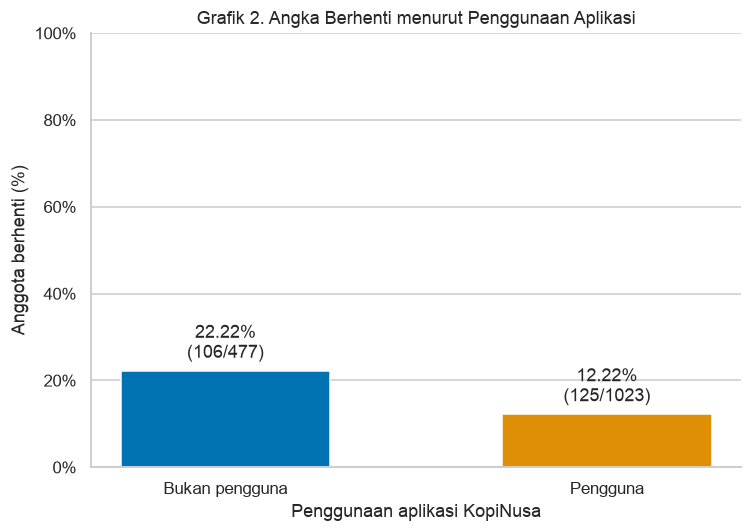

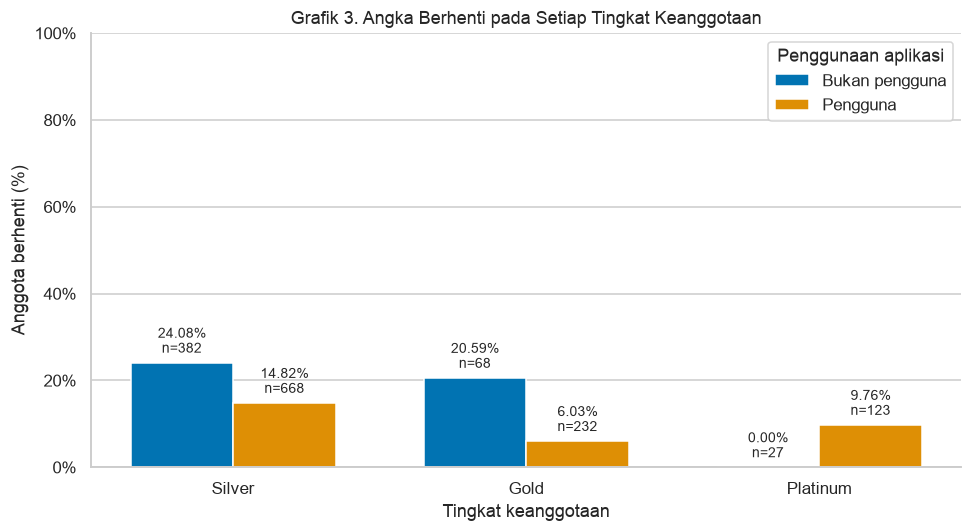

In [69]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter

sns.set_theme(
    style="whitegrid",
    context="notebook",
    palette="colorblind"
)

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "axes.spines.top": False,
    "axes.spines.right": False
})

urutan_aplikasi = ["tidak", "ya"]
urutan_tingkat = ["Silver", "Gold", "Platinum"]
label_aplikasi = ["Bukan pengguna", "Pengguna"]
warna = sns.color_palette("colorblind", 2)

# Grafik 2
fig, ax = plt.subplots(figsize=(7, 5))

batang = ax.bar(
    label_aplikasi,
    ringkasan_aplikasi["persen_berhenti"].to_numpy(),
    color=warna,
    width=0.55
)

label_batang = [
    f"{row.persen_berhenti:.2f}%\n"
    f"({int(row.jumlah_berhenti)}/{int(row.jumlah_anggota)})"
    for row in ringkasan_aplikasi.itertuples()
]

ax.bar_label(batang, labels=label_batang, padding=5)
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.set_title("Grafik 2. Angka Berhenti menurut Penggunaan Aplikasi")
ax.set_xlabel("Penggunaan aplikasi KopiNusa")
ax.set_ylabel("Anggota berhenti (%)")
ax.grid(axis="x", visible=False)

fig.tight_layout()
plt.show()

# Grafik 3
persen_tingkat = (
    ringkasan_tingkat.pivot(
        index="tingkat",
        columns="pakai_aplikasi",
        values="persen_berhenti"
    )
    .reindex(index=urutan_tingkat, columns=urutan_aplikasi)
)

detail_tingkat = ringkasan_tingkat.set_index(
    ["tingkat", "pakai_aplikasi"]
)

fig, ax = plt.subplots(figsize=(9, 5))
posisi = list(range(len(urutan_tingkat)))
lebar = 0.35

for i, aplikasi in enumerate(urutan_aplikasi):
    posisi_batang = [
        x + (i - 0.5) * lebar
        for x in posisi
    ]

    batang = ax.bar(
        posisi_batang,
        persen_tingkat[aplikasi].to_numpy(),
        width=lebar,
        color=warna[i],
        label=label_aplikasi[i]
    )

    label_batang = []

    for tingkat in urutan_tingkat:
        kunci = (tingkat, aplikasi)

        if kunci in detail_tingkat.index:
            row = detail_tingkat.loc[kunci]
            label_batang.append(
                f"{row['persen_berhenti']:.2f}%\n"
                f"n={int(row['jumlah_anggota'])}"
            )
        else:
            label_batang.append("")

    ax.bar_label(batang, labels=label_batang, padding=4, fontsize=9)

ax.set_xticks(posisi)
ax.set_xticklabels(urutan_tingkat)
ax.set_ylim(0, 100)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.set_title("Grafik 3. Angka Berhenti pada Setiap Tingkat Keanggotaan")
ax.set_xlabel("Tingkat keanggotaan")
ax.set_ylabel("Anggota berhenti (%)")
ax.legend(title="Penggunaan aplikasi")
ax.grid(axis="x", visible=False)

fig.tight_layout()
plt.show()

In [70]:
transaksi_belanja = transaksi_nilai.copy()

status_perlu_klarifikasi = [
    "dugaan_salah_skala",
    "total_nol_perlu_klarifikasi",
    "total_negatif_perlu_klarifikasi"
]

status_dikenal = ["tidak_ditandai"] + status_perlu_klarifikasi

assert transaksi_belanja["status_audit_total"].isin(
    status_dikenal
).all(), "Ada status audit yang belum ditangani."

transaksi_belanja["total_analisis"] = (
    transaksi_belanja["total_angka"].astype("Float64")
)

transaksi_belanja.loc[
    transaksi_belanja["status_audit_total"].isin(
        status_perlu_klarifikasi
    ),
    "total_analisis"
] = pd.NA

transaksi_belanja["nominal_belum_terverifikasi"] = (
    transaksi_belanja["total_analisis"].isna()
)

print(
    "Nominal missing untuk analisis pada seluruh transaksi:",
    transaksi_belanja["total_analisis"].isna().sum()
)

pasangan_anggota = transaksi_belanja["id_anggota"].isin(
    anggota_clean["id_anggota"]
)

print(
    "Transaksi tanpa pasangan anggota:",
    (~pasangan_anggota).sum()
)

transaksi_belanja_anggota = transaksi_belanja.loc[
    pasangan_anggota
].copy()

ringkasan_belanja = (
    transaksi_belanja_anggota.groupby(
        "id_anggota",
        observed=True
    )
    .agg(
        jumlah_transaksi=("id_transaksi", "size"),
        jumlah_nominal_belum_terverifikasi=(
            "nominal_belum_terverifikasi", "sum"
        ),
        subtotal_nominal_tersedia=(
            "total_analisis",
            lambda s: s.sum(min_count=1)
        )
    )
    .reset_index()
)

belanja_anggota = anggota_clean[["id_anggota"]].merge(
    ringkasan_belanja,
    on="id_anggota",
    how="left",
    validate="one_to_one",
    indicator="hasil_gabung_belanja"
)

tanpa_transaksi = (
    belanja_anggota["hasil_gabung_belanja"] == "left_only"
)

kolom_jumlah = [
    "jumlah_transaksi",
    "jumlah_nominal_belum_terverifikasi"
]

belanja_anggota[kolom_jumlah] = (
    belanja_anggota[kolom_jumlah].fillna(0).astype(int)
)

# Nol hanya untuk anggota tanpa transaksi yang tercatat pada data ini.
belanja_anggota.loc[
    tanpa_transaksi,
    "subtotal_nominal_tersedia"
] = 0

belanja_anggota["total_belanja_lengkap"] = (
    belanja_anggota["jumlah_nominal_belum_terverifikasi"] == 0
)

belanja_anggota["total_belanja"] = (
    belanja_anggota["subtotal_nominal_tersedia"].where(
        belanja_anggota["total_belanja_lengkap"]
    )
)

assert len(belanja_anggota) == len(anggota_clean)
assert belanja_anggota["id_anggota"].is_unique

print("\nJumlah anggota:", len(belanja_anggota))
print("Anggota tanpa transaksi tercatat:", tanpa_transaksi.sum())
print(
    "Anggota dengan total belum lengkap:",
    (~belanja_anggota["total_belanja_lengkap"]).sum()
)
print(
    "Anggota dengan total lengkap untuk statistik:",
    belanja_anggota["total_belanja"].notna().sum()
)

print("\nAnggota dengan total belum lengkap:")
display(
    belanja_anggota.loc[
        ~belanja_anggota["total_belanja_lengkap"],
        [
            "id_anggota",
            "jumlah_transaksi",
            "jumlah_nominal_belum_terverifikasi",
            "subtotal_nominal_tersedia",
            "total_belanja"
        ]
    ]
)

Nominal missing untuk analisis pada seluruh transaksi: 21
Transaksi tanpa pasangan anggota: 240

Jumlah anggota: 1500
Anggota tanpa transaksi tercatat: 1
Anggota dengan total belum lengkap: 21
Anggota dengan total lengkap untuk statistik: 1479

Anggota dengan total belum lengkap:


,id_anggota,jumlah_transaksi,jumlah_nominal_belum_terverifikasi,subtotal_nominal_tersedia,total_belanja
123,03392,40,1,1715600.0,<NA>
203,00096,21,1,1078200.0,<NA>
383,01067,106,1,9017400.0,<NA>
440,00067,37,1,2202200.0,<NA>
537,01012,26,1,624100.0,<NA>
578,02045,42,1,2016700.0,<NA>
676,03605,21,1,832900.0,<NA>
712,02688,74,1,3056300.0,<NA>
763,03182,39,1,1105100.0,<NA>
769,03793,51,1,2942800.0,<NA>


In [72]:
belanja_untuk_grafik = (
    belanja_anggota["total_belanja"]
    .dropna()
    .astype(float)
)

if belanja_untuk_grafik.empty:
    raise ValueError("Belum ada total belanja lengkap untuk dianalisis.")

rata_rata_belanja = belanja_untuk_grafik.mean()
median_belanja = belanja_untuk_grafik.median()
q1_belanja = belanja_untuk_grafik.quantile(0.25)
q3_belanja = belanja_untuk_grafik.quantile(0.75)
iqr_belanja = q3_belanja - q1_belanja

print("Jumlah anggota yang dianalisis:", len(belanja_untuk_grafik))
print(f"Rata-rata total belanja: Rp{rata_rata_belanja:,.2f}")
print(f"Median total belanja: Rp{median_belanja:,.2f}")
print(f"Q1: Rp{q1_belanja:,.2f}")
print(f"Q3: Rp{q3_belanja:,.2f}")
print(f"IQR: Rp{iqr_belanja:,.2f}")
print(f"Skewness: {belanja_untuk_grafik.skew():.3f}")

display(
    belanja_untuk_grafik.describe(
        percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]
    ).to_frame(name="total_belanja")
)

Jumlah anggota yang dianalisis: 1479
Rata-rata total belanja: Rp1,153,637.29
Median total belanja: Rp879,600.00
Q1: Rp498,950.00
Q3: Rp1,465,700.00
IQR: Rp966,750.00
Skewness: 2.720


,total_belanja
count,1.479000e+03
mean,1.153637e+06
std,1.019453e+06
min,0.000000e+00
25%,4.989500e+05
50%,8.796000e+05
75%,1.465700e+06
95%,3.076210e+06
99%,5.254040e+06
max,1.186710e+07


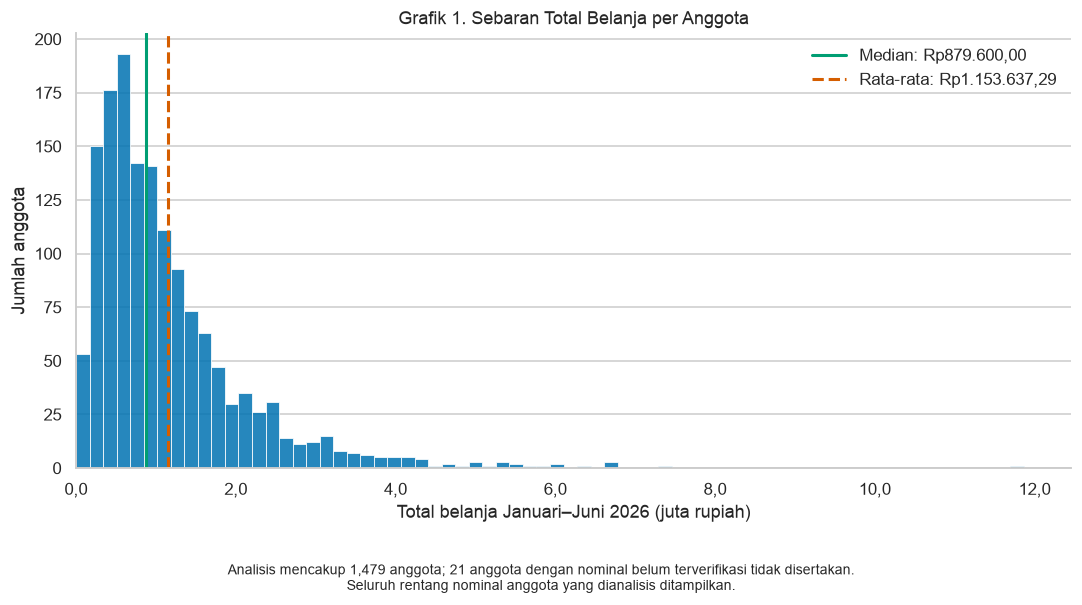

In [73]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

def format_rupiah(nilai):
    return (
        f"Rp{nilai:,.2f}"
        .replace(",", "_")
        .replace(".", ",")
        .replace("_", ".")
    )

jumlah_dianalisis = len(belanja_untuk_grafik)
jumlah_belum_lengkap = (
    ~belanja_anggota["total_belanja_lengkap"]
).sum()

fig, ax = plt.subplots(figsize=(10, 5.5))

ax.hist(
    belanja_untuk_grafik,
    bins="fd",
    color="#0072B2",
    edgecolor="white",
    linewidth=0.6,
    alpha=0.85
)

ax.axvline(
    median_belanja,
    color="#009E73",
    linestyle="-",
    linewidth=2,
    label=f"Median: {format_rupiah(median_belanja)}"
)

ax.axvline(
    rata_rata_belanja,
    color="#D55E00",
    linestyle="--",
    linewidth=2,
    label=f"Rata-rata: {format_rupiah(rata_rata_belanja)}"
)

ax.xaxis.set_major_formatter(
    FuncFormatter(
        lambda nilai, posisi: (
            f"{nilai / 1_000_000:.1f}".replace(".", ",")
        )
    )
)

ax.set_xlim(left=0)
ax.set_ylim(bottom=0)
ax.set_title("Grafik 1. Sebaran Total Belanja per Anggota")
ax.set_xlabel("Total belanja Januari–Juni 2026 (juta rupiah)")
ax.set_ylabel("Jumlah anggota")
ax.legend(frameon=False)
ax.grid(axis="x", visible=False)

fig.text(
    0.5,
    0.01,
    (
        f"Analisis mencakup {jumlah_dianalisis:,} anggota; "
        f"{jumlah_belum_lengkap} anggota dengan nominal belum "
        "terverifikasi tidak disertakan.\n"
        "Seluruh rentang nominal anggota yang dianalisis ditampilkan."
    ),
    ha="center",
    fontsize=9
)

fig.tight_layout(rect=[0, 0.09, 1, 1])
plt.show()

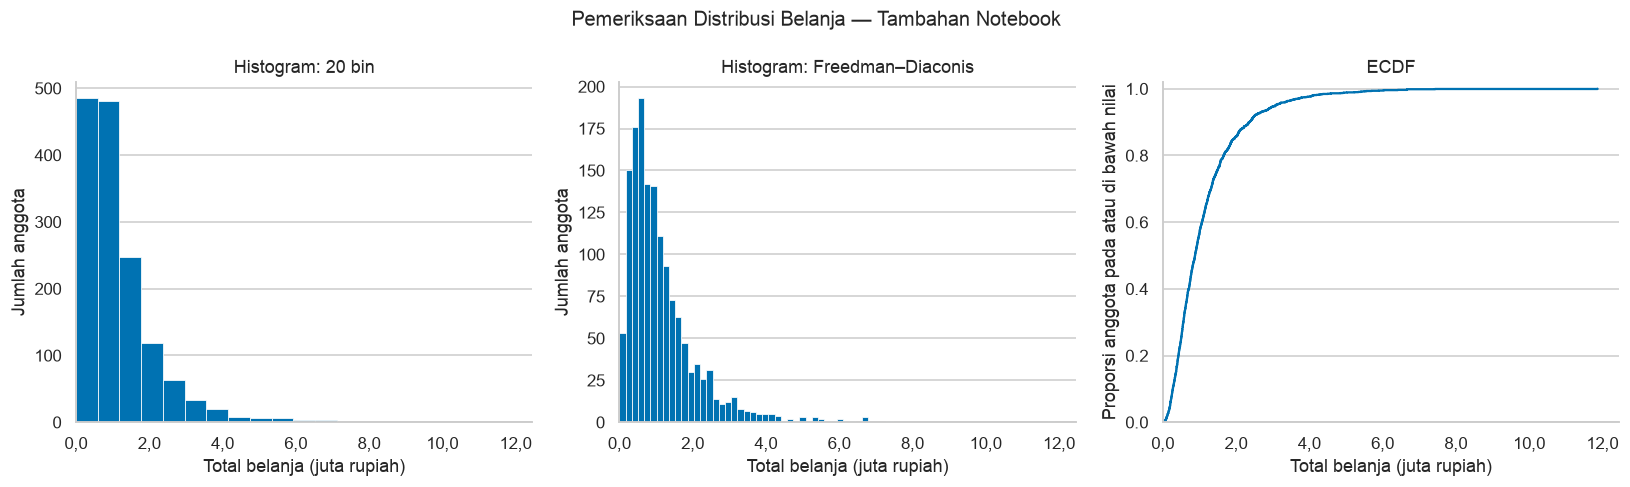

In [74]:
fig, axes = plt.subplots(
    1, 3,
    figsize=(15, 4.5),
    sharex=True
)

for ax, bins, judul in [
    (axes[0], 20, "Histogram: 20 bin"),
    (axes[1], "fd", "Histogram: Freedman–Diaconis")
]:
    ax.hist(
        belanja_untuk_grafik,
        bins=bins,
        color="#0072B2",
        edgecolor="white",
        linewidth=0.5
    )
    ax.set_title(judul)
    ax.set_ylabel("Jumlah anggota")
    ax.set_ylim(bottom=0)

nilai_urut = (
    belanja_untuk_grafik.sort_values().to_numpy()
)

proporsi_kumulatif = (
    pd.Series(range(1, len(nilai_urut) + 1)).to_numpy()
    / len(nilai_urut)
)

axes[2].step(
    nilai_urut,
    proporsi_kumulatif,
    where="post",
    color="#0072B2"
)

axes[2].set_title("ECDF")
axes[2].set_ylabel("Proporsi anggota pada atau di bawah nilai")
axes[2].set_ylim(0, 1.02)

for ax in axes:
    ax.set_xlim(left=0)
    ax.set_xlabel("Total belanja (juta rupiah)")
    ax.xaxis.set_major_formatter(
        FuncFormatter(
            lambda nilai, posisi: (
                f"{nilai / 1_000_000:.1f}".replace(".", ",")
            )
        )
    )
    ax.grid(axis="x", visible=False)

fig.suptitle(
    "Pemeriksaan Distribusi Belanja — Tambahan Notebook",
    fontsize=13
)

fig.tight_layout()
plt.show()

#### 4. Inferensi

Analisis menggunakan seluruh 1.500 anggota, dengan satu baris per<br>
anggota. Nominal transaksi tidak digunakan dalam perhitungan ini.<br>
<br><br>
Misalkan:<br>
- p_aplikasi adalah peluang berhenti pada pengguna aplikasi.<br>
- p_nonaplikasi adalah peluang berhenti pada bukan pengguna aplikasi.<br>
<br><br>
Selisih didefinisikan sebagai:<br>

Delta = p_aplikasi - p_nonaplikasi<br>
<br><br>
Selisih negatif menunjukkan angka berhenti pengguna aplikasi lebih
rendah dari pada bukan pengguna aplikasi.
<br><br>
Hipotesis yang diuji:<br>
- H0: p_aplikasi = p_nonaplikasi.<br>
- H1: p_aplikasi tidak sama dengan p_nonaplikasi.<br>
<br><br>
Digunakan two-proportion z-test dua sisi dengan alpha = 0,05,<br>
mengikuti contoh perbandingan dua proporsi pada Chapter 4.<br>
<br><br>
Selang kepercayaan 95% untuk selisih dihitung menggunakan metode<br>
Newcombe berbasis interval Wilson. Metode ini merupakan implementasi
teknis untuk selisih dua proporsi, sejalan dengan penggunaan Wilson<br>
untuk proporsi dalam modul.
<br><br>
Perhitungan mengasumsikan pengamatan antaranggota independen dan
kedua kelompok merupakan kelompok yang terpisah. Keunikan ID dapat<br>
diperiksa dari tabel, tetapi tidak dengan sendirinya membuktikan
independensi perilaku antaranggota.
<br><br>
Hasil perbandingan sudah dilihat dalam eksplorasi soal 3. Oleh karena<br>
itu, analisis ini tidak diklaim sebagai pengujian pada data baru atau<br>
hipotesis yang didaftarkan sebelum data diperiksa.

In [76]:
%pip install statsmodels

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 44.6 MB/s  0:00:00eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5/5 [statsmodels] [statsmodels]
Note: you may need to restart the kernel to use updated packages.


In [77]:
import numpy as np
import pandas as pd

from statsmodels.stats.proportion import (
    proportions_ztest,
    confint_proportions_2indep
)

anggota_inferensi = anggota_clean[
    ["id_anggota", "pakai_aplikasi", "berhenti"]
].copy()

assert anggota_inferensi["id_anggota"].notna().all()
assert anggota_inferensi["id_anggota"].is_unique

for kolom in ["pakai_aplikasi", "berhenti"]:
    assert anggota_inferensi[kolom].isin(["ya", "tidak"]).all(), (
        f"Ada nilai missing atau kategori tidak sesuai pada {kolom}"
    )

anggota_inferensi["berhenti_flag"] = (
    anggota_inferensi["berhenti"].map({"ya": 1, "tidak": 0})
)

ringkasan_inferensi = (
    anggota_inferensi.groupby("pakai_aplikasi", observed=True)
    .agg(
        jumlah_anggota=("id_anggota", "size"),
        jumlah_berhenti=("berhenti_flag", "sum")
    )
    .reindex(["ya", "tidak"])
)

ringkasan_inferensi["jumlah_bertahan"] = (
    ringkasan_inferensi["jumlah_anggota"]
    - ringkasan_inferensi["jumlah_berhenti"]
)

ringkasan_inferensi["peluang_berhenti"] = (
    ringkasan_inferensi["jumlah_berhenti"]
    / ringkasan_inferensi["jumlah_anggota"]
)

ringkasan_inferensi["persen_berhenti"] = (
    ringkasan_inferensi["peluang_berhenti"] * 100
)

n_aplikasi = int(
    ringkasan_inferensi.loc["ya", "jumlah_anggota"]
)
x_aplikasi = int(
    ringkasan_inferensi.loc["ya", "jumlah_berhenti"]
)

n_nonaplikasi = int(
    ringkasan_inferensi.loc["tidak", "jumlah_anggota"]
)
x_nonaplikasi = int(
    ringkasan_inferensi.loc["tidak", "jumlah_berhenti"]
)

p_aplikasi = x_aplikasi / n_aplikasi
p_nonaplikasi = x_nonaplikasi / n_nonaplikasi
selisih_proporsi = p_aplikasi - p_nonaplikasi

alpha = 0.05

ci_bawah, ci_atas = confint_proportions_2indep(
    count1=x_aplikasi,
    nobs1=n_aplikasi,
    count2=x_nonaplikasi,
    nobs2=n_nonaplikasi,
    compare="diff",
    method="newcomb",
    alpha=alpha
)

proporsi_gabungan = (
    (x_aplikasi + x_nonaplikasi)
    / (n_aplikasi + n_nonaplikasi)
)

z_statistik, p_value = proportions_ztest(
    count=np.array([x_aplikasi, x_nonaplikasi]),
    nobs=np.array([n_aplikasi, n_nonaplikasi]),
    value=0,
    alternative="two-sided",
    prop_var=proporsi_gabungan
)

ekspektasi_h0 = pd.DataFrame(
    {
        "berhenti": [
            n_aplikasi * proporsi_gabungan,
            n_nonaplikasi * proporsi_gabungan
        ],
        "bertahan": [
            n_aplikasi * (1 - proporsi_gabungan),
            n_nonaplikasi * (1 - proporsi_gabungan)
        ]
    },
    index=["pengguna_aplikasi", "bukan_pengguna"]
)

print("Ringkasan anggota:")
display(ringkasan_inferensi.round(6))

print("Frekuensi harapan jika H0 benar:")
display(ekspektasi_h0.round(2))

print(
    "Frekuensi harapan terkecil:",
    round(ekspektasi_h0.to_numpy().min(), 2)
)

hasil_inferensi = pd.DataFrame(
    {
        "ukuran": [
            "P(berhenti | aplikasi)",
            "P(berhenti | bukan aplikasi)",
            "Selisih: aplikasi - bukan aplikasi (pp)",
            "Batas bawah CI 95% selisih (pp)",
            "Batas atas CI 95% selisih (pp)",
            "Statistik z",
            "p-value dua sisi"
        ],
        "nilai": [
            p_aplikasi,
            p_nonaplikasi,
            selisih_proporsi * 100,
            ci_bawah * 100,
            ci_atas * 100,
            z_statistik,
            p_value
        ]
    }
)

print("\nHasil inferensi:")
display(hasil_inferensi)

print(f"\nP(berhenti | aplikasi): {p_aplikasi:.6f}")
print(f"P(berhenti | bukan aplikasi): {p_nonaplikasi:.6f}")
print(f"Selisih: {selisih_proporsi * 100:.3f} poin persentase")
print(
    "CI 95% selisih (Newcombe-Wilson): "
    f"[{ci_bawah * 100:.3f}, {ci_atas * 100:.3f}] "
    "poin persentase"
)
print(f"Statistik z: {z_statistik:.4f}")
print(f"p-value dua sisi: {p_value:.6g}")
print(
    "Keputusan pada alpha = 0,05:",
    "Tolak H0" if p_value < alpha else "Gagal menolak H0"
)

Ringkasan anggota:


,jumlah_anggota,jumlah_berhenti,jumlah_bertahan,peluang_berhenti,persen_berhenti
pakai_aplikasi,,,,,
ya,1023,125,898,0.12219,12.218964
tidak,477,106,371,0.222222,22.222222


Frekuensi harapan jika H0 benar:


,berhenti,bertahan
pengguna_aplikasi,157.54,865.46
bukan_pengguna,73.46,403.54


Frekuensi harapan terkecil: 73.46

Hasil inferensi:


,ukuran,nilai
0,P(berhenti | aplikasi),1.221896e-01
1,P(berhenti | bukan aplikasi),2.222222e-01
2,Selisih: aplikasi - bukan aplikasi (pp),-1.000326e+01
3,Batas bawah CI 95% selisih (pp),-1.436718e+01
4,Batas atas CI 95% selisih (pp),-5.895372e+00
5,Statistik z,-4.998588e+00
6,p-value dua sisi,5.775172e-07



P(berhenti | aplikasi): 0.122190
P(berhenti | bukan aplikasi): 0.222222
Selisih: -10.003 poin persentase
CI 95% selisih (Newcombe-Wilson): [-14.367, -5.895] poin persentase
Statistik z: -4.9986
p-value dua sisi: 5.77517e-07
Keputusan pada alpha = 0,05: Tolak H0


#### Rancangan Percobaan

Acak anggota yang belum memakai aplikasi menjadi dua kelompok dengan
komposisi tingkat keanggotaan seimbang: kelompok perlakuan mendapat
akses dan bantuan aktivasi aplikasi, sedangkan kontrol menerima
layanan biasa. Samakan kebijakan promo kedua kelompok.

Bandingkan persentase anggota yang tidak bertransaksi selama tiga
bulan, berdasarkan kelompok penugasan awal. Sebelum percobaan,
tetapkan efek minimum yang bermakna, ukuran sampel, dan waktu akhir
analisis; laporkan selisih beserta CI 95% dan jangan berhenti hanya
karena hasil sementara signifikan.

Jika tidak semua anggota perlakuan memakai aplikasi, hasil terutama
menunjukkan efek penawaran aplikasi, bukan efek pemakaian aktual.

#### 5. Feature Engineering

##### A. Penyusunan Tabel Pemodelan

Tabel dibuat dengan satu baris per anggota. Fitur menggunakan
transaksi Januari–Juni 2026 untuk memprediksi status berhenti
pada Juli–September 2026.

Fitur RFM:
- recency_days: hari sejak transaksi terakhir hingga 30 Juni 2026.
- frequency: jumlah transaksi unik.
- monetary: rata-rata nilai transaksi.

Fitur tambahan dan hipotesisnya:
- proporsi_promo: anggota yang sering memakai promo mungkin lebih
  mudah berhenti saat promo tidak tersedia.
- bulan_aktif: anggota yang bertransaksi pada lebih banyak bulan
  diduga lebih konsisten datang.
- proporsi_transaksi_juni: rendahnya bagian transaksi pada Juni
  mungkin menunjukkan aktivitas mulai menurun.

Semua anggota tetap disertakan. Monetary yang belum lengkap
dibiarkan kosong, lalu diisi berdasarkan data latih pada setiap
fold agar tidak terjadi kebocoran data.

In [78]:
kolom_transaksi_wajib = [
    "id_transaksi",
    "id_anggota",
    "waktu",
    "pakai_promo",
    "total_analisis"
]

kolom_anggota_wajib = [
    "id_anggota",
    "tanggal_daftar",
    "berhenti"
]

for nama, tabel, kolom_wajib in [
    ("transaksi_belanja", transaksi_belanja, kolom_transaksi_wajib),
    ("anggota_clean", anggota_clean, kolom_anggota_wajib)
]:
    kolom_hilang = [
        kolom for kolom in kolom_wajib
        if kolom not in tabel.columns
    ]

    if kolom_hilang:
        raise ValueError(
            f"Kolom belum tersedia pada {nama}: {kolom_hilang}"
        )

print("Kolom dan tipe data anggota:")
display(
    anggota_clean.dtypes.astype(str)
    .rename("tipe_data")
    .to_frame()
)

print("\nContoh waktu transaksi:")
display(
    transaksi_belanja[
        ["id_transaksi", "id_anggota", "waktu"]
    ].head(10)
)

print("\nTipe kolom waktu:", transaksi_belanja["waktu"].dtype)
print(
    "Waktu transaksi missing:",
    transaksi_belanja["waktu"].isna().sum()
)

print("\nContoh tanggal daftar:")
display(
    anggota_clean[
        ["id_anggota", "tanggal_daftar"]
    ].head(10)
)

print("\nKategori pakai_promo:")
display(
    transaksi_belanja["pakai_promo"]
    .value_counts(dropna=False)
    .rename_axis("pakai_promo")
    .reset_index(name="jumlah_transaksi")
)

print("\nJumlah anggota:", len(anggota_clean))
print(
    "ID anggota unik:",
    anggota_clean["id_anggota"].is_unique
)
print(
    "Jumlah ID transaksi duplikat:",
    transaksi_belanja["id_transaksi"].duplicated().sum()
)

Kolom dan tipe data anggota:


,tipe_data
id_anggota,string
usia,Int64
kota,string
tanggal_daftar,string
tingkat,string
pakai_aplikasi,string
penghasilan_juta,Float64
voucher_winback,string
berhenti,string
penghasilan_was_missing,int8



Contoh waktu transaksi:


,id_transaksi,id_anggota,waktu
0,T009292,03569,2026-02-14 21:03
1,T019288,00318,2026-04-11 07:08
2,T032136,00998,2026-06-15 13:33
3,T026989,00712,2026-05-22 12:53
4,T025743,00208,2026-05-15 14:59
5,T023213,02515,2026-05-02 14:34
6,T018876,01185,2026-04-08 15:50
7,T001776,02071,2026-01-09 12:51
8,T018363,02829,2026-04-05 19:33
9,T025887,03384,2026-05-16 10:42



Tipe kolom waktu: string
Waktu transaksi missing: 0

Contoh tanggal daftar:


,id_anggota,tanggal_daftar
0,00354,12/12/2023
1,01496,12/11/2025
2,02805,05/08/2024
3,00537,24/03/2023
4,03036,07/07/2025
5,01033,11/07/2025
6,00085,08/05/2024
7,03399,22/09/2023
8,03071,06/04/2023
9,01368,28/06/2023



Kategori pakai_promo:


,pakai_promo,jumlah_transaksi
0,tidak,25654
1,ya,9986



Jumlah anggota: 1500
ID anggota unik: True
Jumlah ID transaksi duplikat: 0


In [79]:
tx_fitur = transaksi_belanja.copy()

awal_periode = pd.Timestamp("2026-01-01")
akhir_eksklusif = pd.Timestamp("2026-07-01")
tanggal_acuan = pd.Timestamp("2026-06-30")

tx_fitur["waktu_dt"] = pd.to_datetime(
    tx_fitur["waktu"],
    format="%Y-%m-%d %H:%M",
    errors="coerce"
)

tanggal_gagal = tx_fitur["waktu_dt"].isna()

print("Waktu missing atau gagal dibaca:", tanggal_gagal.sum())

display(
    tx_fitur.loc[
        tanggal_gagal,
        ["id_transaksi", "waktu"]
    ].head(20)
)

if tanggal_gagal.any():
    raise ValueError(
        "Ada waktu yang belum valid. Periksa sebelum menghitung fitur."
    )

dalam_periode = (
    tx_fitur["waktu_dt"].ge(awal_periode)
    & tx_fitur["waktu_dt"].lt(akhir_eksklusif)
)

anggota_dikenal = tx_fitur["id_anggota"].isin(
    anggota_clean["id_anggota"]
)

print("Transaksi di luar Januari–Juni:", (~dalam_periode).sum())
print("Transaksi tanpa pasangan anggota:", (~anggota_dikenal).sum())

tx_fitur = tx_fitur.loc[
    dalam_periode & anggota_dikenal
].copy()

assert tx_fitur["id_transaksi"].is_unique
assert tx_fitur["pakai_promo"].isin(["ya", "tidak"]).all()

tx_fitur["promo_flag"] = (
    tx_fitur["pakai_promo"].map({"ya": 1, "tidak": 0})
)

tx_fitur["bulan"] = tx_fitur["waktu_dt"].dt.to_period("M")

tx_fitur["transaksi_juni"] = (
    tx_fitur["waktu_dt"].dt.month == 6
).astype(int)

tx_fitur["nominal_missing"] = (
    tx_fitur["total_analisis"].isna()
).astype(int)

fitur_transaksi = (
    tx_fitur.groupby("id_anggota", observed=True)
    .agg(
        transaksi_terakhir=("waktu_dt", "max"),
        frequency=("id_transaksi", "nunique"),
        monetary=("total_analisis", "mean"),
        proporsi_promo=("promo_flag", "mean"),
        bulan_aktif=("bulan", "nunique"),
        proporsi_transaksi_juni=("transaksi_juni", "mean"),
        jumlah_nominal_missing=("nominal_missing", "sum")
    )
    .reset_index()
)

fitur_transaksi["recency_days"] = (
    tanggal_acuan
    - fitur_transaksi["transaksi_terakhir"].dt.normalize()
).dt.days

fitur_transaksi.loc[
    fitur_transaksi["jumlah_nominal_missing"] > 0,
    "monetary"
] = pd.NA

print("\nJumlah transaksi yang digunakan:", len(tx_fitur))
print("Anggota dengan transaksi:", len(fitur_transaksi))

display(fitur_transaksi.head())

Waktu missing atau gagal dibaca: 0


,id_transaksi,waktu


Transaksi di luar Januari–Juni: 0
Transaksi tanpa pasangan anggota: 240

Jumlah transaksi yang digunakan: 35400
Anggota dengan transaksi: 1499


,id_anggota,transaksi_terakhir,frequency,monetary,proporsi_promo,bulan_aktif,proporsi_transaksi_juni,jumlah_nominal_missing,recency_days
0,00005,2026-06-27 15:26:00,32,34800.0,0.156250,6,0.218750,0,3
1,00006,2026-06-23 21:07:00,40,62315.0,0.200000,6,0.175000,0,7
2,00008,2026-04-06 14:22:00,7,25600.0,0.571429,4,0.000000,0,85
3,00011,2026-06-18 20:59:00,37,79505.945946,0.189189,6,0.054054,0,12
4,00015,2026-06-17 12:16:00,24,70462.5,0.458333,6,0.083333,0,13


In [80]:
kolom_fitur_transaksi = [
    "id_anggota",
    "recency_days",
    "frequency",
    "monetary",
    "proporsi_promo",
    "bulan_aktif",
    "proporsi_transaksi_juni"
]

tabel_model = anggota_clean.copy().merge(
    fitur_transaksi[kolom_fitur_transaksi],
    on="id_anggota",
    how="left",
    validate="one_to_one",
    indicator="hasil_gabung_fitur"
)

tanpa_transaksi = (
    tabel_model["hasil_gabung_fitur"] == "left_only"
)

for kolom in ["frequency", "bulan_aktif"]:
    tabel_model[kolom] = (
        tabel_model[kolom].fillna(0).astype(int)
    )

tabel_model = tabel_model.drop(columns="hasil_gabung_fitur")

assert tabel_model["berhenti"].isin(["ya", "tidak"]).all()

tabel_model["target_berhenti"] = (
    tabel_model["berhenti"]
    .map({"ya": 1, "tidak": 0})
    .astype(int)
)

assert len(tabel_model) == len(anggota_clean)
assert tabel_model["id_anggota"].is_unique

fitur_baru = [
    "recency_days",
    "frequency",
    "monetary",
    "proporsi_promo",
    "bulan_aktif",
    "proporsi_transaksi_juni"
]

print("Jumlah baris tabel pemodelan:", len(tabel_model))
print("ID anggota unik:", tabel_model["id_anggota"].is_unique)
print("Anggota tanpa transaksi dalam periode:", tanpa_transaksi.sum())

print("\nMissing pada fitur baru:")
display(
    tabel_model[fitur_baru]
    .isna().sum()
    .rename("jumlah_missing")
    .to_frame()
)

print("\nRingkasan fitur:")
display(tabel_model[fitur_baru].describe())

print("\nContoh tabel pemodelan:")
display(
    tabel_model[
        ["id_anggota"] + fitur_baru + ["target_berhenti"]
    ].head(10)
)

Jumlah baris tabel pemodelan: 1500
ID anggota unik: True
Anggota tanpa transaksi dalam periode: 1

Missing pada fitur baru:


,jumlah_missing
recency_days,1
frequency,0
monetary,22
proporsi_promo,1
bulan_aktif,0
proporsi_transaksi_juni,1



Ringkasan fitur:


,recency_days,frequency,monetary,proporsi_promo,bulan_aktif,proporsi_transaksi_juni
count,1499.000000,1500.000000,1478.0,1499.000000,1500.000000,1499.000000
mean,14.358239,23.600000,48992.060871,0.280169,5.241333,0.184374
std,20.885322,18.679988,18739.258076,0.192966,1.027519,0.150800
min,0.000000,0.000000,15633.333333,0.000000,0.000000,0.000000
25%,2.000000,11.000000,36995.535714,0.137931,5.000000,0.071429
50%,6.000000,19.000000,45957.565789,0.250000,6.000000,0.151515
75%,18.000000,29.000000,56961.875,0.400000,6.000000,0.272727
max,153.000000,191.000000,268609.0,1.000000,6.000000,1.000000



Contoh tabel pemodelan:


,id_anggota,recency_days,frequency,monetary,proporsi_promo,bulan_aktif,proporsi_transaksi_juni,target_berhenti
0,00354,2.0,18,38900.0,0.611111,6,0.166667,0
1,01496,58.0,30,39170.0,0.200000,4,0.000000,0
2,02805,4.0,16,34462.5,0.000000,6,0.125000,0
3,00537,0.0,11,28145.454545,0.181818,6,0.090909,0
4,03036,0.0,24,25954.166667,0.375000,6,0.416667,0
5,01033,11.0,14,37871.428571,0.285714,6,0.142857,0
6,00085,89.0,4,48400.0,0.250000,2,0.000000,1
7,03399,10.0,18,72655.555556,0.611111,5,0.111111,0
8,03071,5.0,53,45967.924528,0.509434,6,0.169811,0
9,01368,2.0,55,24672.727273,0.163636,6,0.109091,0


#### 5.A 

In [81]:
import numpy as np
import pandas as pd

data_model = tabel_model.copy()

tanggal_daftar_dt = pd.to_datetime(
    data_model["tanggal_daftar"],
    format="%d/%m/%Y",
    errors="coerce"
)

tanggal_missing = data_model["tanggal_daftar"].isna()

tanggal_gagal = (
    data_model["tanggal_daftar"].notna()
    & tanggal_daftar_dt.isna()
)

tanggal_setelah_cutoff = tanggal_daftar_dt.gt(tanggal_acuan)

print("Tanggal daftar missing:", tanggal_missing.sum())
print("Tanggal daftar gagal dibaca:", tanggal_gagal.sum())
print(
    "Tanggal daftar setelah cutoff:",
    tanggal_setelah_cutoff.sum()
)

display(
    data_model.loc[
        tanggal_gagal | tanggal_setelah_cutoff,
        ["id_anggota", "tanggal_daftar"]
    ]
)

if tanggal_gagal.any() or tanggal_setelah_cutoff.any():
    raise ValueError(
        "Periksa tanggal daftar sebelum melanjutkan."
    )

data_model["lama_anggota_days"] = (
    tanggal_acuan - tanggal_daftar_dt
).dt.days

assert data_model["pakai_aplikasi"].isin(["ya", "tidak"]).all()
assert data_model["tingkat"].isin(
    ["Silver", "Gold", "Platinum"]
).all()

data_model["pakai_aplikasi_flag"] = (
    data_model["pakai_aplikasi"]
    .map({"tidak": 0, "ya": 1})
    .astype(int)
)

assert data_model["penghasilan_was_missing"].isin([0, 1]).all()

data_model.loc[
    data_model["penghasilan_was_missing"].eq(1),
    "penghasilan_juta"
] = pd.NA

fitur_A = [
    "usia",
    "kota",
    "tingkat",
    "pakai_aplikasi_flag",
    "penghasilan_juta",
    "penghasilan_was_missing",
    "lama_anggota_days"
]

fitur_B = fitur_A + [
    "frequency",
    "monetary"
]

fitur_C = fitur_B + [
    "recency_days",
    "proporsi_promo",
    "bulan_aktif",
    "proporsi_transaksi_juni"
]

himpunan_fitur = {
    "A": fitur_A,
    "B": fitur_B,
    "C": fitur_C
}

kolom_numerik = [
    "usia",
    "penghasilan_juta",
    "lama_anggota_days",
    "frequency",
    "monetary",
    "recency_days",
    "proporsi_promo",
    "bulan_aktif",
    "proporsi_transaksi_juni"
]

for kolom in kolom_numerik:
    data_model[kolom] = (
        pd.to_numeric(data_model[kolom], errors="raise")
        .to_numpy(dtype=float, na_value=np.nan)
    )

data_model["kota"] = (
    data_model["kota"].astype(object)
    .where(data_model["kota"].notna(), np.nan)
)

y = data_model["target_berhenti"].astype(int)

for nama, daftar in himpunan_fitur.items():
    print(f"\nHimpunan {nama}: {len(daftar)} kolom")
    print(daftar)

print("\nMissing pada input himpunan C:")
display(
    data_model[fitur_C].isna().sum()
    .rename("jumlah_missing")
    .to_frame()
)

Tanggal daftar missing: 0
Tanggal daftar gagal dibaca: 0
Tanggal daftar setelah cutoff: 0


,id_anggota,tanggal_daftar



Himpunan A: 7 kolom
['usia', 'kota', 'tingkat', 'pakai_aplikasi_flag', 'penghasilan_juta', 'penghasilan_was_missing', 'lama_anggota_days']

Himpunan B: 9 kolom
['usia', 'kota', 'tingkat', 'pakai_aplikasi_flag', 'penghasilan_juta', 'penghasilan_was_missing', 'lama_anggota_days', 'frequency', 'monetary']

Himpunan C: 13 kolom
['usia', 'kota', 'tingkat', 'pakai_aplikasi_flag', 'penghasilan_juta', 'penghasilan_was_missing', 'lama_anggota_days', 'frequency', 'monetary', 'recency_days', 'proporsi_promo', 'bulan_aktif', 'proporsi_transaksi_juni']

Missing pada input himpunan C:


,jumlah_missing
usia,44
kota,0
tingkat,0
pakai_aplikasi_flag,0
penghasilan_juta,138
penghasilan_was_missing,0
lama_anggota_days,0
frequency,0
monetary,22
recency_days,1


#### 5.B

In [82]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    OrdinalEncoder
)

def buat_preprocess(daftar_fitur):
    numerik = [
        kolom for kolom in kolom_numerik
        if kolom in daftar_fitur
    ]

    biner = [
        kolom
        for kolom in [
            "pakai_aplikasi_flag",
            "penghasilan_was_missing"
        ]
        if kolom in daftar_fitur
    ]

    pipeline_numerik = Pipeline([
        ("imputer", SimpleImputer(
            strategy="median",
            add_indicator=True
        )),
        ("scaler", StandardScaler())
    ])

    pipeline_kota = Pipeline([
        ("imputer", SimpleImputer(
            strategy="constant",
            fill_value="Unknown"
        )),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ])

    pipeline_tingkat = Pipeline([
        ("encoder", OrdinalEncoder(
            categories=[["Silver", "Gold", "Platinum"]],
            handle_unknown="use_encoded_value",
            unknown_value=-1
        )),
        ("scaler", StandardScaler())
    ])

    return ColumnTransformer(
        transformers=[
            ("numerik", pipeline_numerik, numerik),
            ("kota", pipeline_kota, ["kota"]),
            ("tingkat", pipeline_tingkat, ["tingkat"]),
            ("biner", "passthrough", biner)
        ],
        remainder="drop"
    )

print("Fungsi preprocessing siap; belum di-fit pada data.")

Fungsi preprocessing siap; belum di-fit pada data.


#### 5.C. Perbandingan Himpunan Fitur

Dua model, logistic regression dan kNN, dibandingkan pada:
- A: fitur dari tabel anggota.
- B: A ditambah frequency dan monetary.
- C: B ditambah recency dan tiga fitur perilaku tambahan.

Evaluasi menggunakan 5-fold cross-validation dan ROC-AUC.
Seluruh kombinasi memakai pembagian fold yang sama.
Imputasi, encoding, dan scaling dilakukan di dalam Pipeline
agar tidak mempelajari data uji.

Parameter ditetapkan sebelum evaluasi: logistic regression
menggunakan C = 1 dan kNN menggunakan k = 15.

In [83]:
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_score
)
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.base import clone

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

folds = list(
    cv.split(data_model[fitur_C], y)
)

model_dasar = {
    "Logistic regression": LogisticRegression(
        C=1.0,
        max_iter=5000,
        solver="lbfgs"
    ),
    "kNN (k=15)": KNeighborsClassifier(
        n_neighbors=15,
        weights="uniform"
    )
}

hasil_cv = []

for nama_himpunan, daftar_fitur in himpunan_fitur.items():
    X = data_model[daftar_fitur]

    for nama_model, estimator in model_dasar.items():
        pipeline_model = Pipeline([
            ("prep", buat_preprocess(daftar_fitur)),
            ("model", clone(estimator))
        ])

        skor = cross_val_score(
            pipeline_model,
            X,
            y,
            cv=folds,
            scoring="roc_auc",
            n_jobs=-1,
            error_score="raise"
        )

        baris = {
            "himpunan": nama_himpunan,
            "jumlah_kolom_awal": len(daftar_fitur),
            "model": nama_model,
            "mean_roc_auc": skor.mean(),
            "std_roc_auc": skor.std(ddof=1)
        }

        for nomor, nilai in enumerate(skor, start=1):
            baris[f"fold_{nomor}"] = nilai

        hasil_cv.append(baris)

hasil_cv = pd.DataFrame(hasil_cv)

display(hasil_cv.round(4))

,himpunan,jumlah_kolom_awal,model,mean_roc_auc,std_roc_auc,fold_1,fold_2,fold_3,fold_4,fold_5
0,A,7,Logistic regression,0.5915,0.0366,0.6509,0.5859,0.5965,0.5572,0.5669
1,A,7,kNN (k=15),0.5655,0.0496,0.5795,0.4841,0.5563,0.6025,0.6053
2,B,9,Logistic regression,0.6075,0.0405,0.6749,0.5746,0.6114,0.5790,0.5975
3,B,9,kNN (k=15),0.5838,0.0365,0.6348,0.5668,0.6084,0.5476,0.5612
4,C,13,Logistic regression,0.8226,0.0231,0.8632,0.8163,0.8165,0.8106,0.8065
5,C,13,kNN (k=15),0.7744,0.0268,0.8074,0.7591,0.7608,0.7983,0.7463


In [84]:
tabel_laporan_cv = hasil_cv[
    ["himpunan", "model", "mean_roc_auc", "std_roc_auc"]
].copy()

tabel_laporan_cv["ROC-AUC (mean ± SD)"] = [
    f"{rata:.4f} ± {sd:.4f}"
    for rata, sd in zip(
        tabel_laporan_cv["mean_roc_auc"],
        tabel_laporan_cv["std_roc_auc"]
    )
]

print("Tabel hasil untuk laporan:")
display(
    tabel_laporan_cv[
        ["himpunan", "model", "ROC-AUC (mean ± SD)"]
    ]
)

tabel_perbandingan = (
    hasil_cv.pivot(
        index="model",
        columns="himpunan",
        values="mean_roc_auc"
    )
    .reindex(columns=["A", "B", "C"])
)

tabel_perbandingan["perubahan_B_minus_A"] = (
    tabel_perbandingan["B"] - tabel_perbandingan["A"]
)

tabel_perbandingan["perubahan_C_minus_B"] = (
    tabel_perbandingan["C"] - tabel_perbandingan["B"]
)

print("Perubahan rata-rata ROC-AUC:")
display(tabel_perbandingan.round(4))

Tabel hasil untuk laporan:


,himpunan,model,ROC-AUC (mean ± SD)
0,A,Logistic regression,0.5915 ± 0.0366
1,A,kNN (k=15),0.5655 ± 0.0496
2,B,Logistic regression,0.6075 ± 0.0405
3,B,kNN (k=15),0.5838 ± 0.0365
4,C,Logistic regression,0.8226 ± 0.0231
5,C,kNN (k=15),0.7744 ± 0.0268


Perubahan rata-rata ROC-AUC:


himpunan,A,B,C,perubahan_B_minus_A,perubahan_C_minus_B
model,,,,,
Logistic regression,0.5915,0.6075,0.8226,0.0160,0.2151
kNN (k=15),0.5655,0.5838,0.7744,0.0182,0.1906


#### D. Pemeriksaan Kolom yang Tidak Boleh Menjadi Fitur

ID anggota tidak digunakan sebagai fitur karena hanya merupakan
kode pengenal. Kolom berhenti dan target_berhenti merupakan target,
sehingga tidak boleh dimasukkan ke input model.

Voucher_winback juga dikeluarkan karena voucher dikirim pada
Agustus 2026, setelah batas fitur 30 Juni 2026. Memakainya akan
menyebabkan kebocoran informasi masa depan.

Pemeriksaan dilakukan pada asal informasi setiap kolom dan daftar
fitur A, B, serta C.

In [85]:
kolom_dilarang = [
    "id_anggota",
    "berhenti",
    "target_berhenti",
    "voucher_winback"
]

print("Pemeriksaan ID anggota:")
print("Jumlah baris:", len(data_model))
print("Jumlah ID unik:", data_model["id_anggota"].nunique())

print("\nPemeriksaan kesesuaian target:")
target_dari_teks = (
    data_model["berhenti"].map({"tidak": 0, "ya": 1})
)

print(
    "target_berhenti sama dengan hasil encoding berhenti:",
    target_dari_teks.eq(data_model["target_berhenti"]).all()
)

print("\nHubungan voucher dengan status berhenti:")
tabel_voucher = pd.crosstab(
    data_model["voucher_winback"],
    data_model["berhenti"],
    dropna=False
)

display(tabel_voucher)

print(
    "\nKeterangan dokumen soal: voucher dikirim Agustus 2026; "
    "batas fitur adalah 30 Juni 2026."
)

hasil_audit_fitur = []

for nama, daftar_fitur in himpunan_fitur.items():
    ditemukan = sorted(
        set(daftar_fitur).intersection(kolom_dilarang)
    )

    hasil_audit_fitur.append({
        "himpunan": nama,
        "jumlah_kolom_terlarang": len(ditemukan),
        "kolom_terlarang": ", ".join(ditemukan) or "-"
    })

    assert not ditemukan, (
        f"Ada kolom terlarang pada himpunan {nama}: {ditemukan}"
    )

print("\nPemeriksaan input model:")
display(pd.DataFrame(hasil_audit_fitur))

Pemeriksaan ID anggota:
Jumlah baris: 1500
Jumlah ID unik: 1500

Pemeriksaan kesesuaian target:
target_berhenti sama dengan hasil encoding berhenti: True

Hubungan voucher dengan status berhenti:


berhenti,tidak,ya
voucher_winback,,
0,1232,40
1,37,191



Keterangan dokumen soal: voucher dikirim Agustus 2026; batas fitur adalah 30 Juni 2026.

Pemeriksaan input model:


,himpunan,jumlah_kolom_terlarang,kolom_terlarang
0,A,0,-
1,B,0,-
2,C,0,-


#### E. PCA pada Fitur Numerik

PCA dilakukan pada sembilan fitur numerik: usia, penghasilan,
lama keanggotaan, frequency, monetary, recency, proporsi promo,
bulan aktif, dan proporsi transaksi Juni.

Nilai kosong diisi median, lalu fitur menggunakan StandardScaler.
Jumlah komponen dipilih berdasarkan variansi kumulatif minimal 90%.
PC1 ditafsirkan dari fitur dengan loading absolut terbesar.

PCA ini digunakan untuk merangkum data, terpisah dari evaluasi model
pada 5.C. Target, ID, kategori, dan penanda biner tidak disertakan.

In [86]:
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

fitur_pca = [
    "usia",
    "penghasilan_juta",
    "lama_anggota_days",
    "frequency",
    "monetary",
    "recency_days",
    "proporsi_promo",
    "bulan_aktif",
    "proporsi_transaksi_juni"
]

X_pca = data_model[fitur_pca].copy()

if X_pca.isna().all().any():
    raise ValueError("Ada fitur PCA yang seluruh nilainya kosong.")

pipeline_pca = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("pca", PCA(svd_solver="full"))
])

skor_pca = pipeline_pca.fit_transform(X_pca)
pca = pipeline_pca.named_steps["pca"]

variansi = pca.explained_variance_ratio_
variansi_kumulatif = np.cumsum(variansi)

jumlah_komponen_90 = int(
    np.searchsorted(variansi_kumulatif, 0.90) + 1
)

tabel_variansi_pca = pd.DataFrame({
    "komponen": [
        f"PC{i}" for i in range(1, len(variansi) + 1)
    ],
    "variansi_persen": variansi * 100,
    "kumulatif_persen": variansi_kumulatif * 100
})

print("Jumlah fitur numerik:", len(fitur_pca))
print("Jumlah anggota:", len(X_pca))
print("Komponen untuk minimal 90% variansi:", jumlah_komponen_90)

print(
    "Variansi kumulatif pada jumlah tersebut:",
    f"{variansi_kumulatif[jumlah_komponen_90 - 1] * 100:.2f}%"
)

display(tabel_variansi_pca.round(3))

Jumlah fitur numerik: 9
Jumlah anggota: 1500
Komponen untuk minimal 90% variansi: 7
Variansi kumulatif pada jumlah tersebut: 90.72%


,komponen,variansi_persen,kumulatif_persen
0,PC1,22.469,22.469
1,PC2,13.556,36.025
2,PC3,12.792,48.817
3,PC4,12.374,61.191
4,PC5,11.083,72.273
5,PC6,9.746,82.020
6,PC7,8.704,90.724
7,PC8,6.815,97.539
8,PC9,2.461,100.000


Variansi yang dijelaskan PC1: 22.47%

Loading PC1:


,fitur,loading_PC1,loading_absolut
0,recency_days,0.6100,0.6100
1,bulan_aktif,-0.5428,0.5428
2,frequency,-0.4563,0.4563
3,proporsi_transaksi_juni,-0.3324,0.3324
4,usia,0.0893,0.0893
5,proporsi_promo,0.0696,0.0696
6,monetary,-0.0362,0.0362
7,lama_anggota_days,0.0171,0.0171
8,penghasilan_juta,0.0109,0.0109


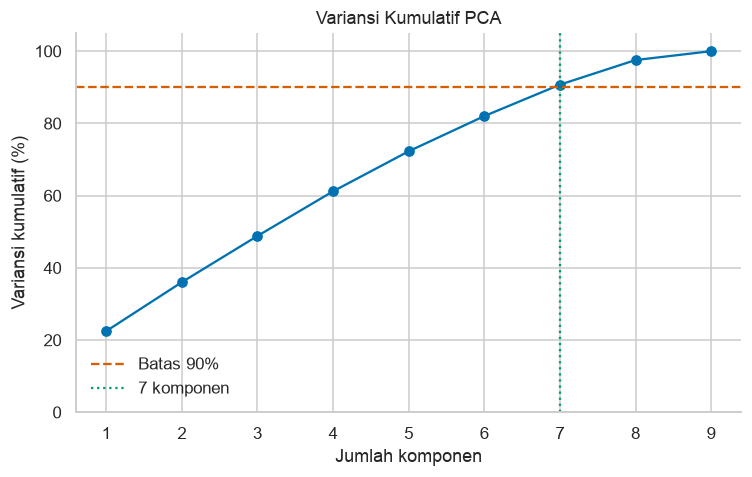

In [87]:
loading_pc1 = pd.DataFrame({
    "fitur": fitur_pca,
    "loading_PC1": pca.components_[0]
})

loading_pc1["loading_absolut"] = (
    loading_pc1["loading_PC1"].abs()
)

loading_pc1 = loading_pc1.sort_values(
    "loading_absolut",
    ascending=False
).reset_index(drop=True)

print(f"Variansi yang dijelaskan PC1: {variansi[0] * 100:.2f}%")
print("\nLoading PC1:")
display(loading_pc1.round(4))

nomor_komponen = np.arange(1, len(variansi) + 1)

fig, ax = plt.subplots(figsize=(7, 4.5))

ax.plot(
    nomor_komponen,
    variansi_kumulatif * 100,
    marker="o",
    color="#0072B2"
)

ax.axhline(
    90,
    color="#D55E00",
    linestyle="--",
    label="Batas 90%"
)

ax.axvline(
    jumlah_komponen_90,
    color="#009E73",
    linestyle=":",
    label=f"{jumlah_komponen_90} komponen"
)

ax.set_xticks(nomor_komponen)
ax.set_ylim(0, 105)
ax.set_xlabel("Jumlah komponen")
ax.set_ylabel("Variansi kumulatif (%)")
ax.set_title("Variansi Kumulatif PCA")
ax.legend(frameon=False)

fig.tight_layout()
plt.show()

#### Ekspor tabel pemodelan

In [88]:
from pathlib import Path

kolom_ekspor = ["id_anggota"] + fitur_C + ["target_berhenti"]

tabel_model_ekspor = data_model[kolom_ekspor].copy()

assert len(tabel_model_ekspor) == 1500
assert tabel_model_ekspor["id_anggota"].is_unique

folder_output = Path("output")
folder_output.mkdir(exist_ok=True)

file_csv = folder_output / "tabel_pemodelan_kopinusa.csv"

tabel_model_ekspor.to_csv(
    file_csv,
    index=False,
    encoding="utf-8-sig"
)

# Baca kembali untuk memeriksa hasil ekspor.
cek_csv = pd.read_csv(
    file_csv,
    dtype={"id_anggota": "string"}
)

assert len(cek_csv) == len(tabel_model_ekspor)
assert cek_csv["id_anggota"].equals(
    tabel_model_ekspor["id_anggota"].astype("string").reset_index(drop=True)
)
assert file_csv.stat().st_size > 0

print("CSV berhasil disimpan dan diperiksa.")
print("Jumlah baris:", len(cek_csv))
print("Jumlah kolom:", len(cek_csv.columns))
print("Lokasi file:", file_csv.resolve())

display(cek_csv.head())

CSV berhasil disimpan dan diperiksa.
Jumlah baris: 1500
Jumlah kolom: 15
Lokasi file: /Users/otnansirk/S2-MMI/data-science-uts/notebooks/output/tabel_pemodelan_kopinusa.csv


,id_anggota,usia,kota,tingkat,pakai_aplikasi_flag,penghasilan_juta,penghasilan_was_missing,lama_anggota_days,frequency,monetary,recency_days,proporsi_promo,bulan_aktif,proporsi_transaksi_juni,target_berhenti
0,00354,41.0,Yogyakarta,Silver,1,11.8,0,931.0,18.0,38900.000000,2.0,0.611111,6.0,0.166667,0
1,01496,20.0,Sleman,Silver,1,8.8,0,230.0,30.0,39170.000000,58.0,0.200000,4.0,0.000000,0
2,02805,35.0,Bantul,Silver,1,3.9,0,694.0,16.0,34462.500000,4.0,0.000000,6.0,0.125000,0
3,00537,29.0,Sleman,Silver,1,6.1,0,1194.0,11.0,28145.454545,0.0,0.181818,6.0,0.090909,0
4,03036,35.0,Yogyakarta,Silver,0,8.8,0,358.0,24.0,25954.166667,0.0,0.375000,6.0,0.416667,0
